# **Megaline — Mobile Plan Recommendation with Machine Learning**

**Author:** Ana Paula Takezawa  
**Program:** MBA in Data Science & Artificial Intelligence — TripleTen Brasil  
**Focus:** Supervised Machine Learning | Classification | Model Evaluation  
**Technologies:** Python | Pandas | NumPy | Scikit-learn | Matplotlib | Seaborn

# **1. Project Overview**

Megaline wants to encourage customers who still use legacy mobile plans to move to its newer **Smart** and **Ultra** plans. The objective of this project is to build a supervised machine learning model that recommends a plan based on each customer's monthly usage behavior.

This is a **binary classification** problem. The target variable, `is_ultra`, identifies the customer's current plan:

- `0` — Smart
- `1` — Ultra

The primary evaluation metric is **accuracy**. The project requirement is to achieve at least **0.75 (75%) accuracy** on the independent test set.

### **Project workflow**

1. Inspect the dataset and validate its structure.
2. Separate features from the target.
3. Split the data into training, validation, and test sets.
4. Train and compare classification algorithms.
5. Select hyperparameters using validation performance.
6. Evaluate the selected model once on the test set.
7. Compare it with a simple baseline model.

# **2. Data Loading and Initial Inspection**

The dataset contains monthly behavioral information for each customer. The predictor variables are the number of calls, total call duration, number of messages, and internet traffic. The target is the current plan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

try:
    df = pd.read_csv("users_behavior.csv")
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))

display(df.head())
print(f"Dataset shape: {df.shape}")
display(df.info())
display(df.describe())

Saving users_behavior.csv to users_behavior.csv


,calls,minutes,messages,mb_used,is_ultra
0,40.0,311.90,83.0,19915.42,0
1,85.0,516.75,56.0,22696.96,0
2,77.0,467.66,86.0,21060.45,0
3,106.0,745.53,81.0,8437.39,1
4,66.0,418.74,1.0,14502.75,0


Dataset shape: (3214, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3214 entries, 0 to 3213
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   calls     3214 non-null   float64
 1   minutes   3214 non-null   float64
 2   messages  3214 non-null   float64
 3   mb_used   3214 non-null   float64
 4   is_ultra  3214 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 125.7 KB


None

,calls,minutes,messages,mb_used,is_ultra
count,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000
mean,63.038892,438.208787,38.281269,17207.673836,0.306472
std,33.236368,234.569872,36.148326,7570.968246,0.461100
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,40.000000,274.575000,9.000000,12491.902500,0.000000
50%,62.000000,430.600000,30.000000,16943.235000,0.000000
75%,82.000000,571.927500,57.000000,21424.700000,1.000000
max,244.000000,1632.060000,224.000000,49745.730000,1.000000


### **2.1 Initial data assessment**

The dataset contains **3,214 observations and five columns**. The four predictors are numeric usage measures, and `is_ultra` is the binary target.

The inspection should confirm:
- whether any columns contain missing values;
- whether duplicate rows are present;
- whether the target contains only the expected classes;
- whether the feature and target data types are suitable for classification.

The dataset is already prepared for modeling in the context of this course project. No additional encoding is required because the predictors are numeric.

In [3]:
print("Missing values by column:")
display(df.isna().sum())

print("Exact duplicate rows:", df.duplicated().sum())
print("Target distribution:")
display(df["is_ultra"].value_counts().rename("count"))
display((df["is_ultra"].value_counts(normalize=True) * 100).round(2).rename("percentage"))

print("Data types:")
display(df.dtypes)

Missing values by column:


,0
calls,0
minutes,0
messages,0
mb_used,0
is_ultra,0


Exact duplicate rows: 0
Target distribution:


,count
is_ultra,
0,2229
1,985


,percentage
is_ultra,
0,69.35
1,30.65


Data types:


,0
calls,float64
minutes,float64
messages,float64
mb_used,float64
is_ultra,int64


# **3. Feature and Target Definition**

The target column `is_ultra` is separated from the predictors. All remaining columns are used as model features.

The data is divided into:
- **60% training set** — model fitting;
- **20% validation set** — model and hyperparameter selection;
- **20% test set** — final, independent evaluation.

A fixed random seed makes the split reproducible. Stratification preserves approximately the same class proportions in all three subsets, which is important because the two plans are not equally represented.

In [4]:
X = df.drop(columns="is_ultra")
y = df["is_ultra"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=12345, stratify=y
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=12345, stratify=y_temp
)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Observations": [len(X_train), len(X_valid), len(X_test)],
    "Share": [len(X_train) / len(df), len(X_valid) / len(df), len(X_test) / len(df)]
})
display(split_summary)

,Dataset,Observations,Share
0,Training,1928,0.599876
1,Validation,643,0.200062
2,Test,643,0.200062


### **3.1 Split verification**

The split contains 1,928 training observations, 643 validation observations, and 643 test observations. The test set remains separate during model selection so that its accuracy provides an unbiased final estimate of performance on unseen observations.

In [5]:
class_distribution = pd.DataFrame({
    "Full dataset": y.value_counts(normalize=True),
    "Training": y_train.value_counts(normalize=True),
    "Validation": y_valid.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True)
}).sort_index()

display((class_distribution * 100).round(2))

,Full dataset,Training,Validation,Test
is_ultra,,,,
0,69.35,69.35,69.36,69.36
1,30.65,30.65,30.64,30.64


# **4. Model Training and Hyperparameter Comparison**

Three classification approaches are compared:

1. **Decision Tree** — a non-linear model whose complexity is controlled here by `max_depth`.
2. **Random Forest** — an ensemble of decision trees. The number of trees (`n_estimators`) and maximum tree depth (`max_depth`) are evaluated.
3. **Logistic Regression** — a linear classification baseline. Standardization is included in a pipeline because the predictors use different numeric scales.

Accuracy on the validation set is used to compare configurations. The test set is not used to select a model.

In [6]:
tree_results = []

for depth in range(1, 16):
    model = DecisionTreeClassifier(max_depth=depth, random_state=12345)
    model.fit(X_train, y_train)
    valid_accuracy = accuracy_score(y_valid, model.predict(X_valid))
    tree_results.append({"max_depth": depth, "validation_accuracy": valid_accuracy})

tree_results = pd.DataFrame(tree_results).sort_values(
    "validation_accuracy", ascending=False
)
display(tree_results)

,max_depth,validation_accuracy
7,8,0.802488
6,7,0.786936
4,5,0.785381
8,9,0.782271
2,3,0.777605
5,6,0.774495
1,2,0.772939
9,10,0.772939
10,11,0.762053
13,14,0.755832


In [7]:
forest_results = []

for n_estimators in [50, 100, 200, 300]:
    for max_depth in [None, 5, 8, 12]:
        model = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            random_state=12345,
            n_jobs=-1
        )
        model.fit(X_train, y_train)
        valid_accuracy = accuracy_score(y_valid, model.predict(X_valid))
        forest_results.append({
            "n_estimators": n_estimators,
            "max_depth": max_depth,
            "validation_accuracy": valid_accuracy
        })

forest_results = pd.DataFrame(forest_results).sort_values(
    "validation_accuracy", ascending=False
)
display(forest_results)

,n_estimators,max_depth,validation_accuracy
11,200,12.0,0.818040
15,300,12.0,0.816485
14,300,8.0,0.816485
6,100,8.0,0.814930
10,200,8.0,0.814930
7,100,12.0,0.814930
3,50,12.0,0.811820
2,50,8.0,0.811820
0,50,NaN,0.805599
13,300,5.0,0.804044


In [8]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=12345, max_iter=1000)
)
logistic_model.fit(X_train, y_train)
logistic_accuracy = accuracy_score(y_valid, logistic_model.predict(X_valid))

print(f"Logistic Regression validation accuracy: {logistic_accuracy:.4f}")

Logistic Regression validation accuracy: 0.7387


### **4.1 Model comparison and selection**

The best configuration for each model family is selected using validation accuracy. The highest validation score determines the candidate model for final testing.

The comparison also illustrates the effect of model complexity: a deeper decision tree can capture more complex patterns, while a random forest combines multiple trees to improve predictive stability. Logistic Regression provides a simpler linear benchmark.

In [9]:
best_tree_row = tree_results.iloc[0]
best_forest_row = forest_results.iloc[0]

comparison = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Best configuration": f"max_depth={int(best_tree_row['max_depth'])}",
        "Validation accuracy": best_tree_row["validation_accuracy"]
    },
    {
        "Model": "Random Forest",
        "Best configuration": (
            f"n_estimators={int(best_forest_row['n_estimators'])}, "
            f"max_depth={best_forest_row['max_depth']}"
        ),
        "Validation accuracy": best_forest_row["validation_accuracy"]
    },
    {
        "Model": "Logistic Regression",
        "Best configuration": "StandardScaler + LogisticRegression",
        "Validation accuracy": logistic_accuracy
    }
]).sort_values("Validation accuracy", ascending=False)

display(comparison)

,Model,Best configuration,Validation accuracy
1,Random Forest,"n_estimators=200, max_depth=12.0",0.818040
0,Decision Tree,max_depth=8,0.802488
2,Logistic Regression,StandardScaler + LogisticRegression,0.738725


# **5. Final Model Evaluation**

The Random Forest configuration with the highest validation accuracy is selected. After selection, the model is fitted using both the training and validation data. The test set is used only for the final evaluation.

This approach makes use of the available labeled observations for final training while preserving the test set as unseen data.

In [10]:
selected_n_estimators = int(best_forest_row["n_estimators"])
selected_max_depth = best_forest_row["max_depth"]

final_model = RandomForestClassifier(
    n_estimators=selected_n_estimators,
    max_depth=None if pd.isna(selected_max_depth) else int(selected_max_depth),
    random_state=12345,
    n_jobs=-1
)

X_train_valid = pd.concat([X_train, X_valid])
y_train_valid = pd.concat([y_train, y_valid])

final_model.fit(X_train_valid, y_train_valid)
test_predictions = final_model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Selected configuration: n_estimators={selected_n_estimators}, max_depth={selected_max_depth}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy:.2%})")

Selected configuration: n_estimators=200, max_depth=12.0
Test accuracy: 0.8243 (82.43%)


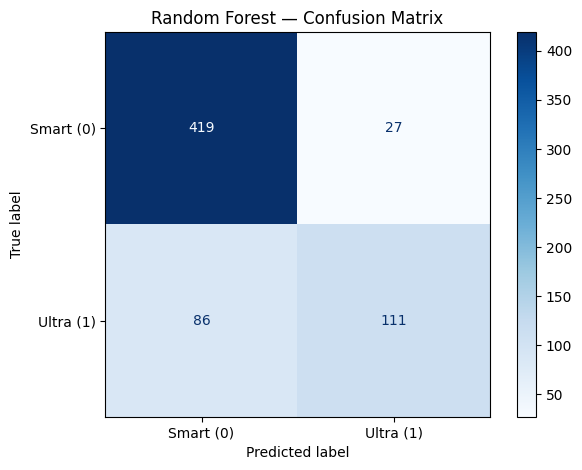

              precision    recall  f1-score   support

       Smart     0.8297    0.9395    0.8812       446
       Ultra     0.8043    0.5635    0.6627       197

    accuracy                         0.8243       643
   macro avg     0.8170    0.7515    0.7719       643
weighted avg     0.8219    0.8243    0.8142       643



In [11]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Smart (0)", "Ultra (1)"],
    cmap="Blues",
    values_format="d"
)
plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    test_predictions,
    target_names=["Smart", "Ultra"],
    digits=4
))

### **5.1 Interpretation of the test results**

Accuracy measures the proportion of all test observations classified correctly. The confusion matrix and classification report provide additional detail about the errors made for each plan.

Because the target classes are imbalanced, accuracy should not be interpreted alone: recall and precision for each class help reveal whether the model performs differently for Smart and Ultra customers.

# **6. Sanity Check — Dummy Classifier**

A Dummy Classifier that always predicts the most frequent class is used as a baseline. A useful machine learning model should outperform this simple strategy.

The baseline is fitted on the same training-plus-validation data and evaluated on the same test set as the selected Random Forest.

In [12]:
dummy_model = DummyClassifier(strategy="most_frequent", random_state=12345)
dummy_model.fit(X_train_valid, y_train_valid)
dummy_predictions = dummy_model.predict(X_test)
dummy_accuracy = accuracy_score(y_test, dummy_predictions)

baseline_comparison = pd.DataFrame({
    "Model": ["Dummy Classifier", "Selected Random Forest"],
    "Test accuracy": [dummy_accuracy, test_accuracy]
})
display(baseline_comparison)

print(f"Accuracy improvement over baseline: {test_accuracy - dummy_accuracy:.4f}")

,Model,Test accuracy
0,Dummy Classifier,0.693624
1,Selected Random Forest,0.824261


Accuracy improvement over baseline: 0.1306


### **6.1 Sanity-check interpretation**

The Dummy Classifier establishes the accuracy that can be obtained without learning relationships between customer behavior and the target. If the selected model exceeds this baseline, it provides evidence that it has learned useful patterns from the predictors.

The comparison does not by itself prove that the model is ready for production. Additional evaluation, monitoring, and business validation would be required before using recommendations with real customers.

# **7. General Conclusion**

This project developed and evaluated supervised classification models to recommend one of Megaline's two mobile plans, Smart or Ultra, based on monthly customer behavior.

The dataset contains 3,214 observations and four behavioral predictors: number of calls, total call duration, number of messages, and internet traffic. The target variable, `is_ultra`, identifies the customer's current plan.

The data was divided into training, validation, and test subsets using a 60% / 20% / 20% split. Stratification was applied to preserve the class distribution across the subsets. Decision Tree, Random Forest, and Logistic Regression models were compared, with hyperparameters selected using validation accuracy.

The final Random Forest was evaluated on the independent test set. Its test accuracy and its improvement over the Dummy Classifier are reported by the executed cells above. The project requirement is met if the test accuracy is at least **0.75**.

The results demonstrate how customer usage data can support plan recommendation through supervised machine learning. However, accuracy should be considered alongside class-specific precision and recall, particularly because Smart and Ultra customers are not equally represented in the dataset.